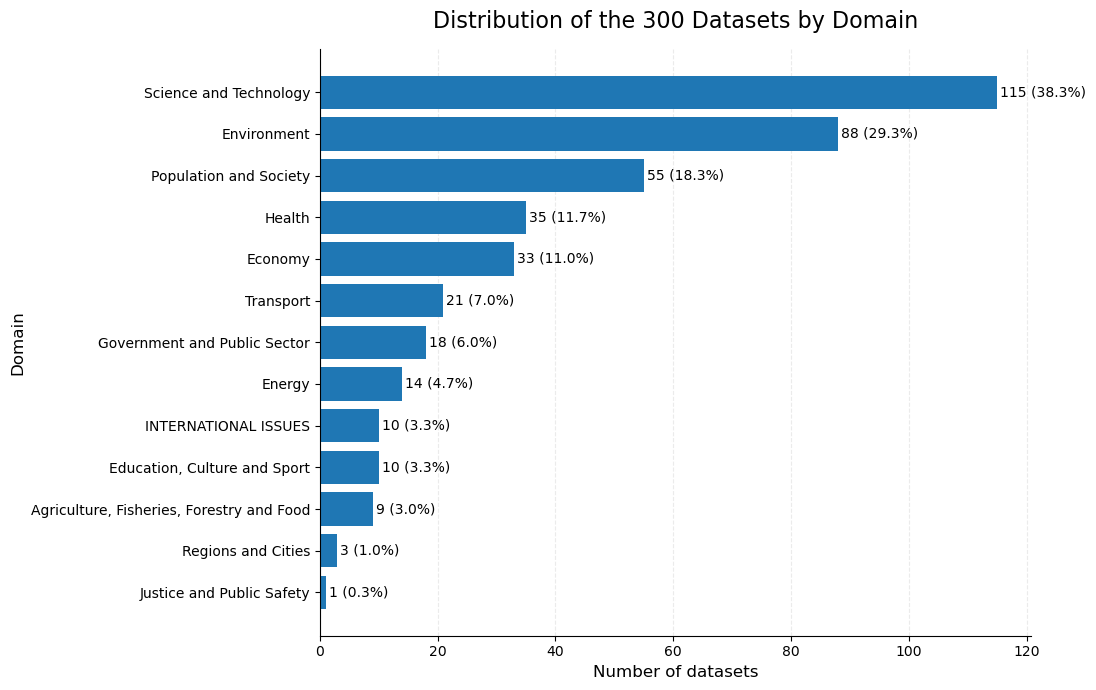

In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt

# Load the JSON file
with open("gov_data_be_sampled_300.json", "r", encoding="utf-8") as f:
    data = json.load(f)

# Extract all domains
domains = []

for dataset in data:
    domains.extend(dataset.get("domains", []))

# Count datasets in each domain
domain_counts = pd.Series(domains).value_counts()

# Total number of datasets
total_datasets = len(data)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(11, 7))

counts = domain_counts.sort_values()

bars = ax.barh(
    counts.index,
    counts.values
)

# Add count and percentage to each bar
for bar, count in zip(bars, counts.values):

    percentage = (count / total_datasets) * 100

    ax.text(
        bar.get_width() + 0.5,
        bar.get_y() + bar.get_height() / 2,
        f"{count} ({percentage:.1f}%)",
        va="center",
        fontsize=10
    )

# Labels and title
ax.set_title(
    "Distribution of the 300 Datasets by Domain",
    fontsize=16,
    pad=15
)

ax.set_xlabel("Number of datasets", fontsize=12)
ax.set_ylabel("Domain", fontsize=12)

# Cleaner appearance
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "datasets_by_domain.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()